### Import Library & Load Dataset Mentah

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur agar angka desimal tidak menggunakan notasi ilmiah (scientific notation)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

df_raw = pd.read_csv('../dataset/jakarta_house.csv')
print(f"Dataset awal berhasil dimuat! Ukuran data: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
display(df_raw.head())

Dataset awal berhasil dimuat! Ukuran data: 10000 baris, 9 kolom


,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.00,350.00
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.00,225.00
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.00,140.00
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.00,120.00
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.00,108.00


### Pilih Kolom Utama & Cek Informasi Data

In [44]:
kolom_digunakan = [
    'price', 'district', 'city', 'bed_rooms', 
    'bath_rooms', 'carport', 'land_area', 'building_area'
]
df_filtered = df_raw[kolom_digunakan].copy()

print("INFORMASI TIPE DATA:")
print(df_filtered.info())

print("\nSTATISTIK DESKRIPTIF DATA MENTAH:")
display(df_filtered.describe().T)

INFORMASI TIPE DATA:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          10000 non-null  int64  
 1   district       10000 non-null  str    
 2   city           10000 non-null  str    
 3   bed_rooms      10000 non-null  int64  
 4   bath_rooms     10000 non-null  int64  
 5   carport        10000 non-null  int64  
 6   land_area      9997 non-null   float64
 7   building_area  9995 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 859.5 KB
None

STATISTIK DESKRIPTIF DATA MENTAH:


,count,mean,std,min,25%,50%,75%,max
price,10000.00,10040290040.00,20045186721.57,1850000.00,2500000000.00,4500000000.00,9800000000.00,900000000000.00
bed_rooms,10000.00,4.25,3.18,0.00,3.00,4.00,5.00,63.00
bath_rooms,10000.00,3.52,2.90,0.00,2.00,3.00,4.00,63.00
carport,10000.00,1.58,1.74,0.00,1.00,1.00,2.00,31.00
land_area,9997.00,296.61,502.92,1.00,100.00,177.00,335.00,17714.00
building_area,9995.00,319.96,357.68,1.00,139.00,230.00,400.00,15331.00


### Cek Mising Value dan Duplikat

In [45]:
print("JUMLAH MISSING VALUE:")
print(df_filtered.isnull().sum())

print("\nJUMLAH DATA DUPLIKAT:", df_filtered.duplicated().sum())

JUMLAH MISSING VALUE:
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        3
building_area    5
dtype: int64

JUMLAH DATA DUPLIKAT: 526


### Visualiasai Distribusi Data Numerik

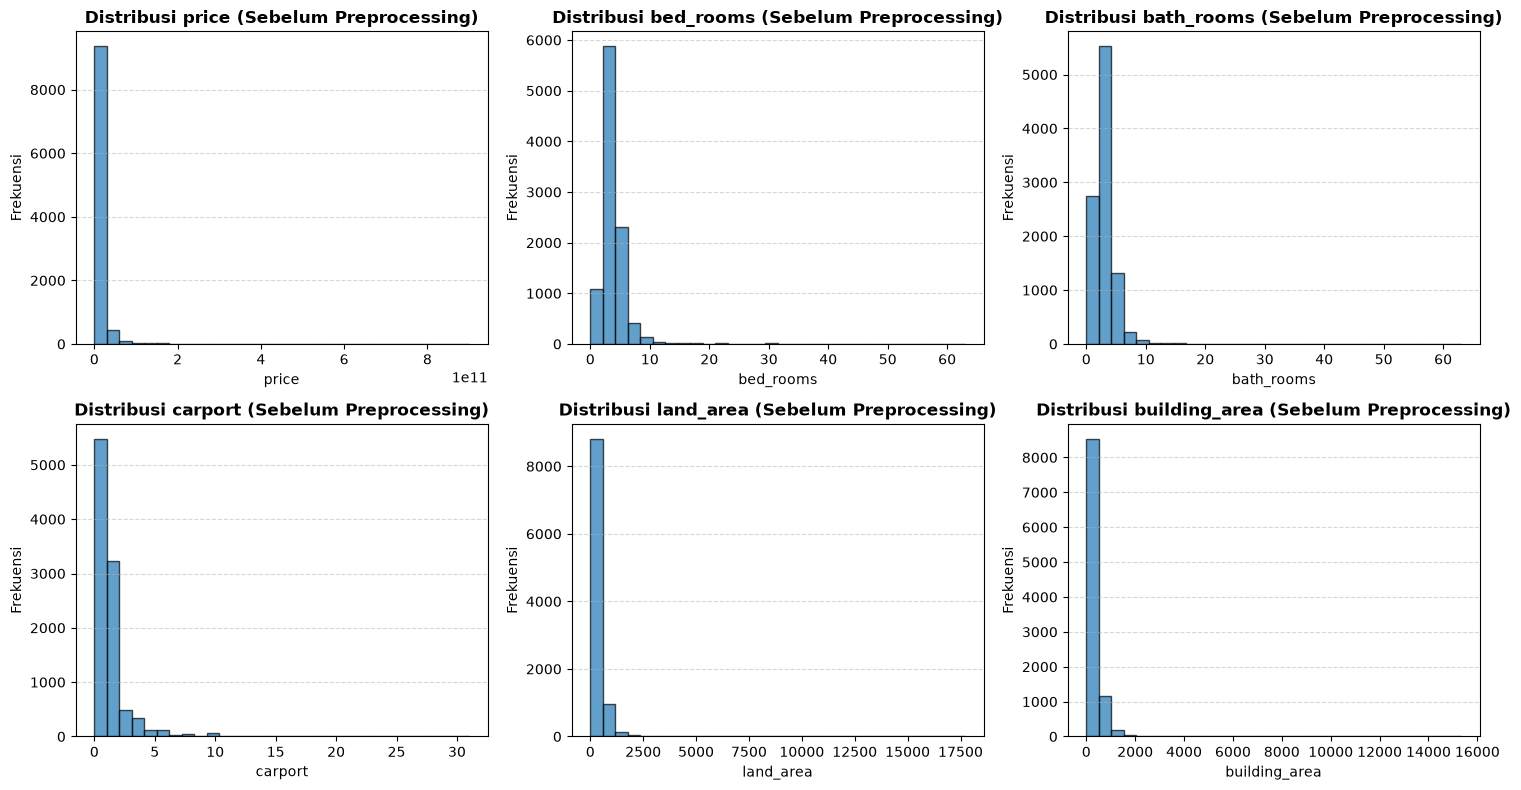

In [51]:
kolom_numerik = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_numerik):
    axes[i].hist(df_filtered[col].dropna(), bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribusi {col} (Sebelum Preprocessing)', fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Visualisasi Distribusi Data City

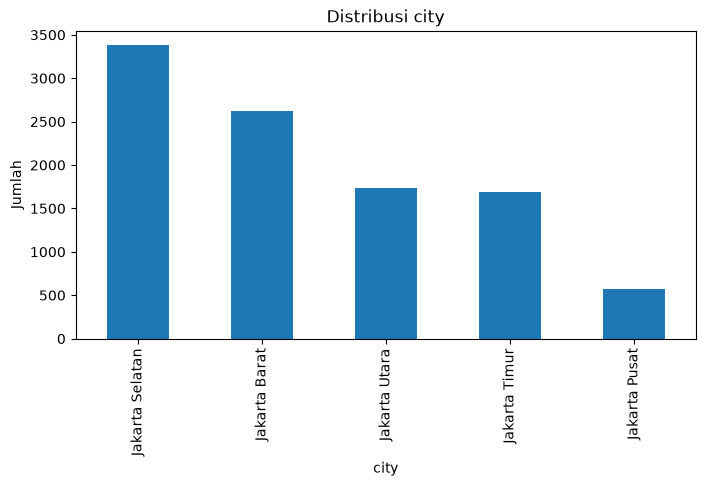

In [47]:
kolom_city = ['city']

for col in kolom_city:
    plt.figure(figsize=(8,4))
    df_filtered[col].value_counts().plot(kind='bar')
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Jumlah')
    plt.show()

### Visualisasi Outlier dengan Boxplot

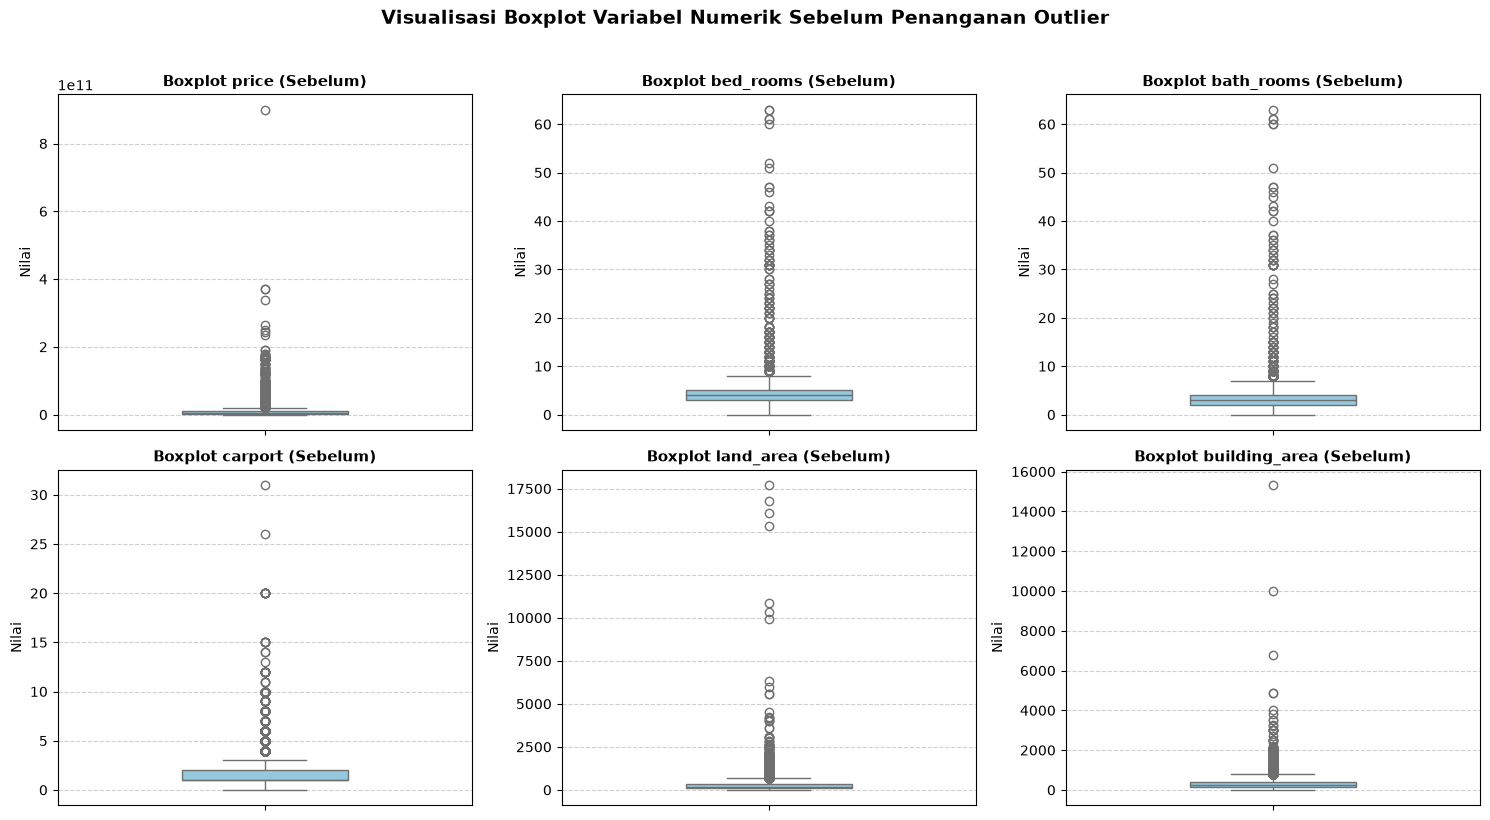

In [48]:
kolom_numerik = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_numerik):
    sns.boxplot(y=df_filtered[col].dropna(), ax=axes[i], color='skyblue', width=0.4)
    axes[i].set_title(f'Boxplot {col} (Sebelum)', fontweight='bold', fontsize=11)
    axes[i].set_ylabel('Nilai')
    axes[i].grid(axis='y', linestyle='--', alpha=0.6)

plt.suptitle('Visualisasi Boxplot Variabel Numerik Sebelum Penanganan Outlier', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Korelasi Antar Fitur

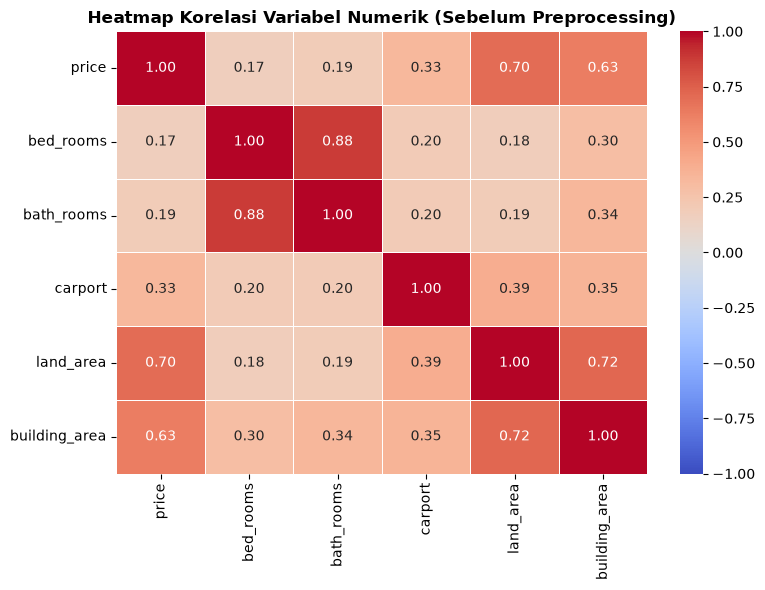

In [60]:
kolom_numerik = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

corr_sebelum = df_filtered[kolom_numerik].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_sebelum,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Heatmap Korelasi Variabel Numerik (Sebelum Preprocessing)', fontweight='bold')
plt.tight_layout()
plt.show()

### Korelasi Terhadap Target (Price)

In [58]:
kolom_numerik = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

corr_sebelum['price'].sort_values(ascending=False)

price           1.00
land_area       0.70
building_area   0.63
carport         0.33
bath_rooms      0.19
bed_rooms       0.17
Name: price, dtype: float64